___
<a href='https://cafe.naver.com/jmhonglab'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 디지털 이미지 연습문제

앞에서 Pillow를 통해 사용해본 이미지 조작/변환 알고리즘들 중 몇 가지를 Numpy를 이용해서 직접 구현해보겠습니다. 결과를 눈으로 볼 수 있기 때문에 좋은 파이썬 프로그래밍 연습이 될 뿐 아니라 나중에 코테준비(특히 2차원 배열을 사용하는 중급 이상 문제들)에 도움이 크게 됩니다.

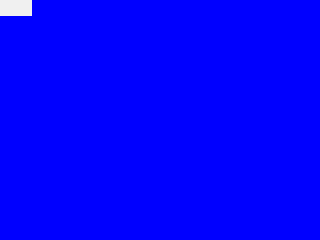

In [1]:
# 이미지 좌표계 확인
from PIL import Image
import numpy as np

# 배열 초기화
arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8) # 15=높이 20=너비 3=컬러. Height, Width, Colors (HWC). 
#모든 값을 0,0,255로 초기화

# 점 찍기
arr[0,0] = (240, 240, 240) # Gray color
arr[0,1] = (240, 240, 240) # Gray color

# Pillow Image로 변환 (clip, astype). clip으로 0~255로 범위제한, astype으로 uint8(0~255 사이 정수를 다루는 자료형)로 변환
im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
# 픽셀을 분명하게 보기 위해서 NEAREST로 upsampling
im = im.resize((320, 240), resample=Image.NEAREST)
im

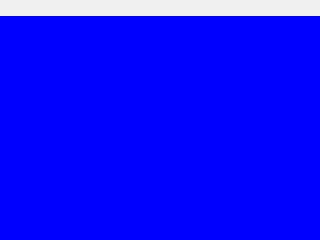

In [14]:
# (0, 0) -> (19, 0) 가로 직선
from PIL import Image
import numpy as np

arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8)

##############
pass
#arr[0:19,0] = (240, 240, 240) # Gray color
for i in range(0, 20):
    arr[0, i] = (240, 240, 240)
##############

im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im = im.resize((320, 240), resample=Image.NEAREST)
im

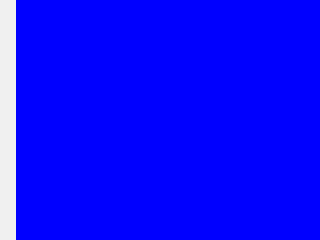

In [13]:
# (0, 0) -> (0, 14) 세로 직선
from PIL import Image
import numpy as np

arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8)


##############
pass
for j in range(0, 15):
    arr[j, 0] = (240, 240, 240)
##############


im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im = im.resize((320, 240), resample=Image.NEAREST)
im

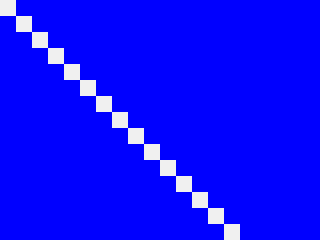

In [15]:
# (0, 0) -> (14, 14) 45도 기울어진 선분 그리기
from PIL import Image
import numpy as np

arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8)


##############
pass
for j in range(0, 15):
    arr[j, j] = (240, 240, 240)
##############


im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im = im.resize((320, 240), resample=Image.NEAREST)
im

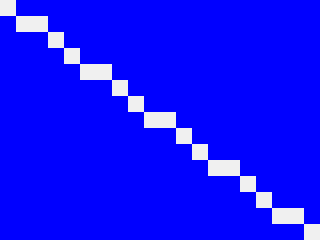

In [16]:
# (0, 0) -> (19, 14) 임의의 기울기를 가진 선분 (Pillow)
from PIL import Image, ImageDraw
import numpy as np

im = Image.new("RGB", (20, 15), (0, 0, 255))

d = ImageDraw.Draw(im)

d.line((0,0,19,14), fill=(240,240,240))

im = im.resize((320, 240), resample=Image.NEAREST)

im


(0, 0)에서 (19, 14)로 임의의 기울기를 가진 선분 그리기

1. 일반적인 [직선의 방정식](https://terms.naver.com/entry.naver?docId=5685306&cid=40942&categoryId=32223)은 $y = ax + b$ 형태이다. 여기서 $a$는 $x$가 증가할때 $y$가 증가하는 비율인 기울기이고 $b$는 이 직선이 $y$ 축과 만나는 $y$ 절편이다.
1. 주어진 문제에서 $a$와 $b$를 구하면 $x$에 대해 $y$가 몇 인지를 계산할 수 있다.
1. (0, 0)을 지나기 때문에 $b$는 0이다.
1. $x$ 방향으로 0에서 19, $y$ 방향으로 0에서 14로 이동하기 때문에 기울기 $a = 14/19$ 이다.
1. 예를 들어서 $x$가 3일 때 $y = 14/19 \times x + 0 = 2.21$이다. 정수 인덱스를 얻기 위해 반올림을 하면 round(2.21)은 2이기 때문에 (3, 2)에 점을 찍는다.

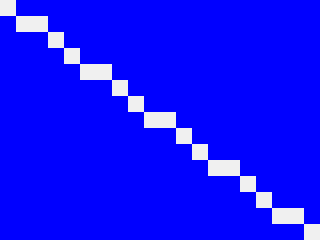

In [25]:
# (0, 0) -> (19, 14) 임의의 기울기를 가진 선분
from PIL import Image
import numpy as np

arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8)

# ###
a = 14 / 19 #기울기
for j in range(0, 20):
    arr[round(a*j), j] = (240, 240, 240)
###

im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im = im.resize((320, 240), resample=Image.NEAREST)
im

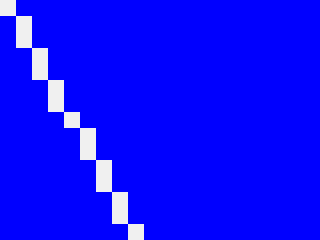

In [29]:
# (0, 0) -> (8, 14) 임의의 기울기를 가진 선분
from PIL import Image
import numpy as np

arr = np.full((15, 20, 3), (0, 0, 255), dtype=np.uint8)


###
a = 8/14 #기울기
for j in range(0, 15):
    arr[j, round(a*j)] = (240, 240, 240)
###


im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im = im.resize((320, 240), resample=Image.NEAREST)
im

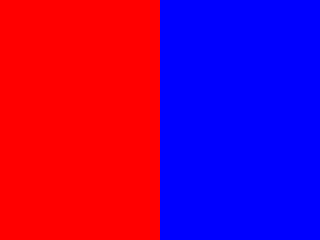

In [35]:
# 좌우 나누기
from PIL import Image
import numpy as np

arr = np.full((240, 320, 3), (0, 0, 255), dtype=np.uint8)


###
arr[:, 0:160] = (255, 0, 0)
###


im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기

im

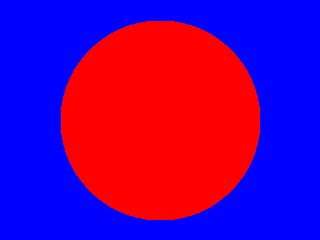

In [4]:
# 원 그리기
from PIL import Image
import numpy as np

arr = np.empty((240, 320, 3), dtype=np.uint8)

#print(arr.shape[0], arr.shape[1])
###
for j in range(arr.shape[0]):
    for i in range(arr.shape[1]):
        arr[j, i] = (255, 0, 0) if (i-160)**2 + (j-120)**2 < 100**2 else (0, 0, 255) # if-else 한줄로 줄여쓰기!
###
#[도전 문제] 원 그리기 문제에서 2중 for루프를 없애보세요. 
#힌트: np.fromfunction(), np.expand_dims()


im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기

im

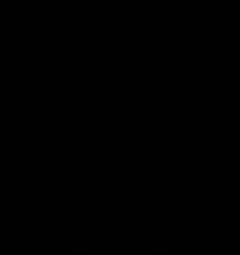

In [8]:
from PIL import Image
import numpy as np
#[도전 문제] 원 그리기 문제에서 2중 for루프를 없애보세요. 
#힌트: np.fromfunction(), np.expand_dims()
#arr = np.fromfunction(lambda i, j: (255, 0, 0) if (i-160)**2 + (j-120)**2 < 100**2 else (0, 0, 255), (255, 240, 3), dtype=np.uint8)
#np.expand_dims

im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im

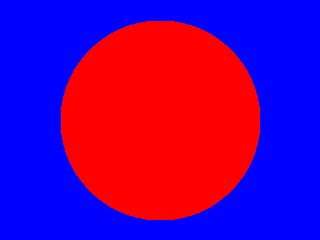

In [25]:
#[도전 문제] 원 그리기 문제에서 2중 for루프를 없애보세요. 
#힌트: np.fromfunction(), np.expand_dims()

from PIL import Image
import numpy as np
check = np.fromfunction(lambda j, i: (j-120)**2 + (i-160)**2 < 100**2, (240, 320), dtype=np.float32)
#print(check.shape)
#print(check)
check = np.expand_dims(check, 2)
#print(check.shape)
#print(check)
arr = check * np.array((255, 0, 0)) + (1.0 - check) * np.array((0, 0, 255))
im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im

[[[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]

 [[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]

 [[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]

 ...

 [[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]

 [[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]

 [[  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]
  ...
  [  0.   0. 255.]
  [  0.   0. 255.]
  [  0.   0. 255.]]]


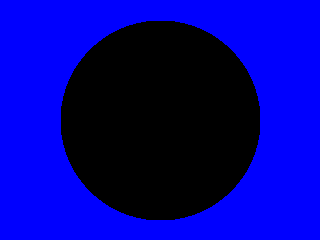

In [28]:
#arr = check * np.array((255, 0, 0)) + (1.0 - check) * np.array((0, 0, 255))
#print(check)
#print(check * np.array((255, 0, 0)))
print((1.0-check)*np.array([0,0,255]))
arr=(1.0-check)*np.array([0,0,255])
im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기
im

(540, 960, 3) uint8


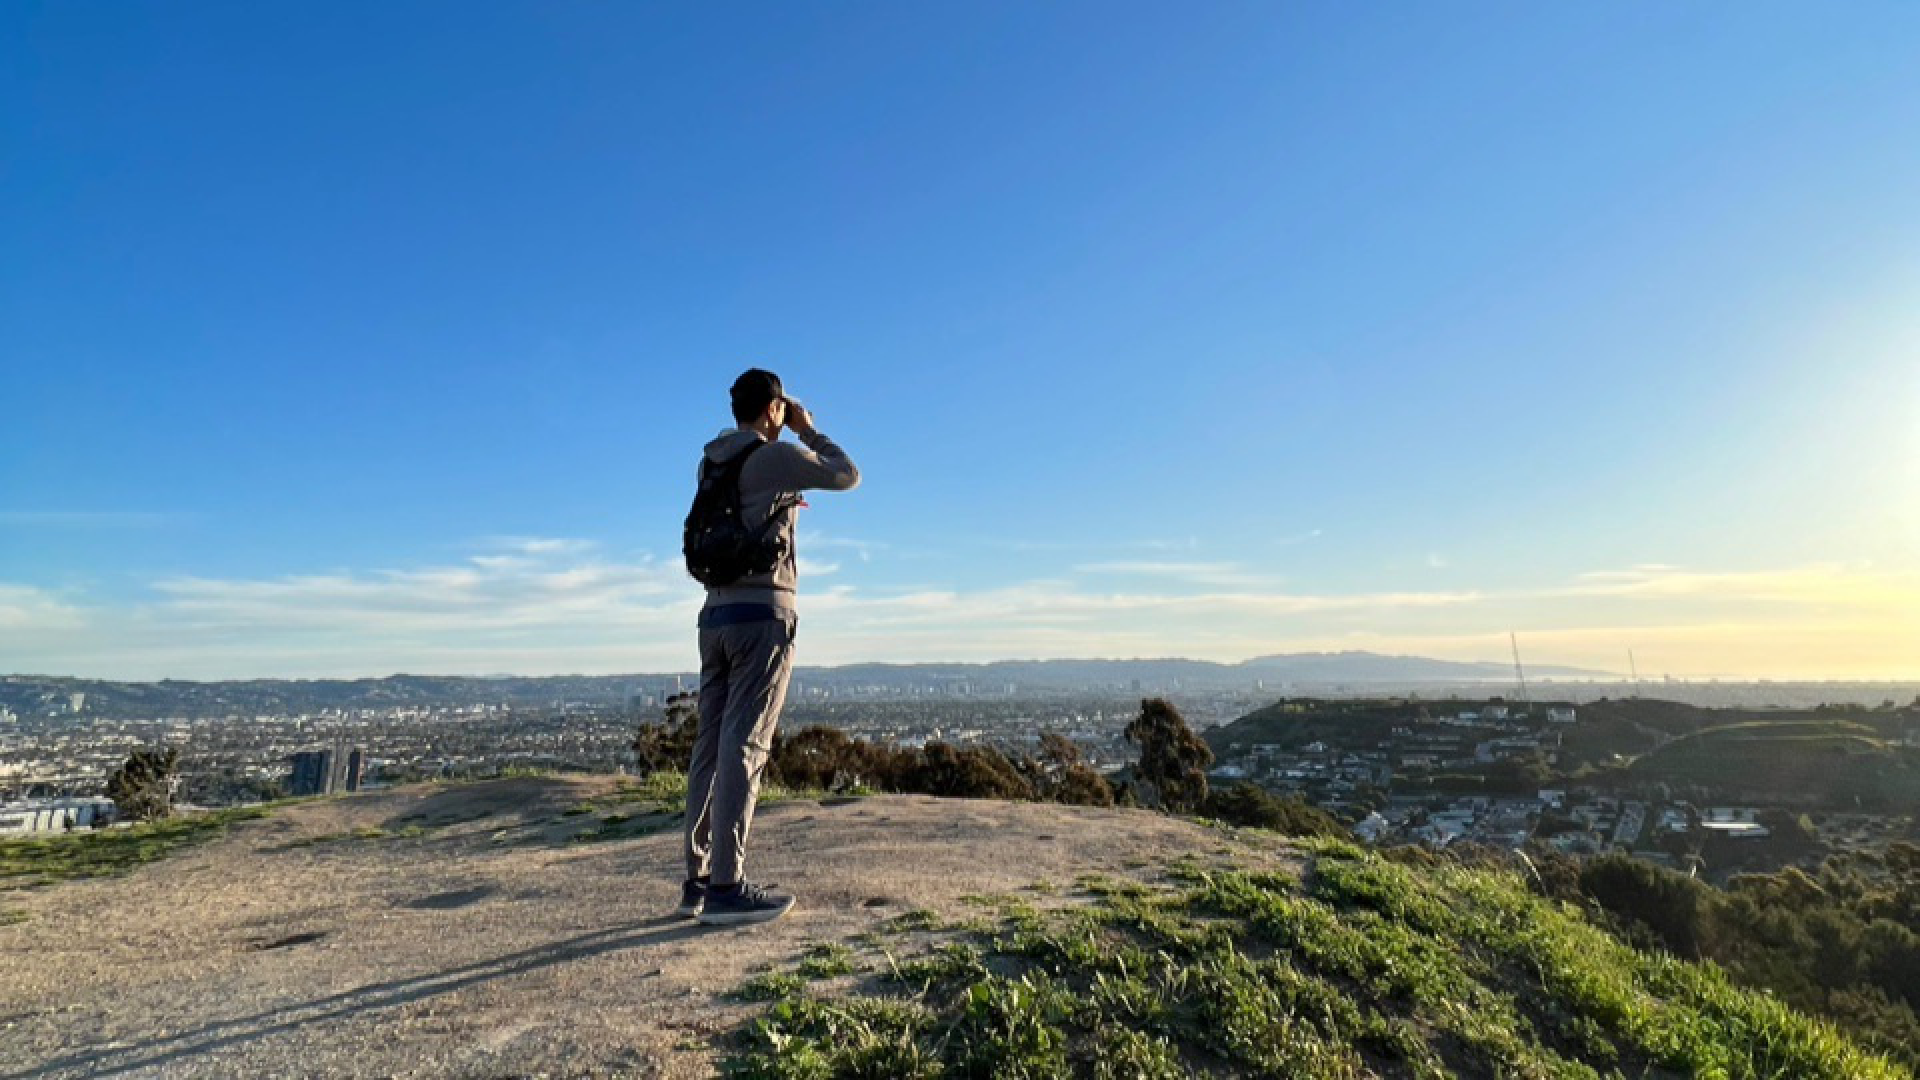

In [29]:
# hflip, vflip, 4분의 1로 downsize
from PIL import Image
import numpy as np

im = Image.open("baldwin_hills.jpg")

#print(im.size) # (960, 540)

arr = np.asarray(im)
print(arr.shape, arr.dtype) # (540, 960, 3) uint8

arr = arr[:, ::-1] # hflip
# arr = arr[::-1, :] # vfilp
# arr = arr[::4, ::4] # 해상도 (1/4)^2로 줄이기
# print(arr.shape)

arr = arr.repeat(2, axis=0).repeat(2, axis=1) # 해상도 높이기 (같은 값 반복)

im = Image.fromarray(arr)#.resize((480, 270))

im

힌트: ```ValueError: assignment destination is read-only``` 오류가 발생할 경우에는 [.copy()](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.copy.html)를 사용해보세요.

(540, 960, 3) uint8
(540, 960, 3)


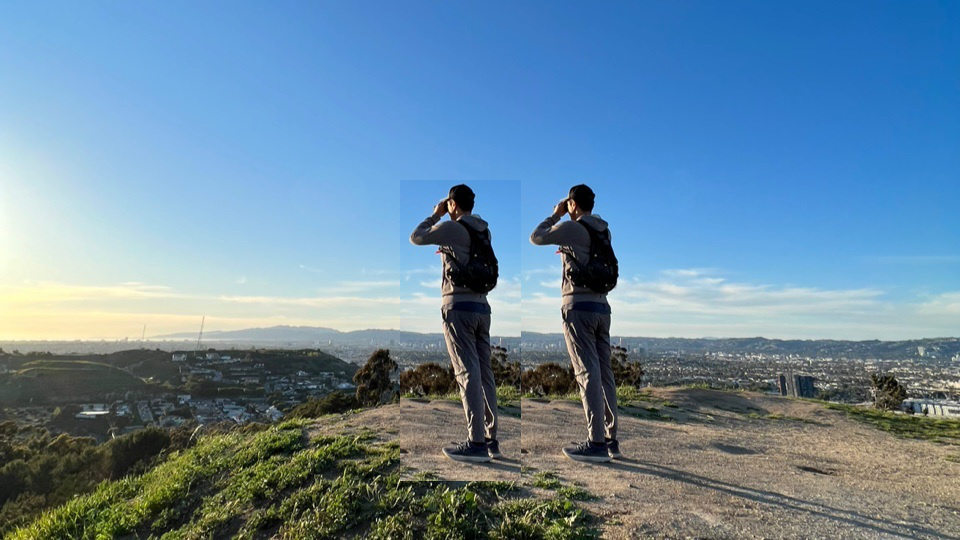

In [60]:
# crop and paste

from PIL import Image
import numpy as np

im = Image.open("baldwin_hills.jpg")

#print(im.size) # (960, 540)

arr = np.asarray(im)
print(arr.shape, arr.dtype) # (540, 960, 3) uint8

###
arr[180:480, 400:520] = arr[180:480, 520:640]
# cropped = arr[180:481, 520:641]
# arr[180:481, 400:521] = cropped
# print(arr.shape)
###

im = Image.fromarray(arr)

im

반투명한 박스를 그려보겠습니다. [Pillow의 alpha_composite](https://github.com/python-pillow/Pillow/blob/95cff6e959bb3c37848158ed2145d49d49806a31/src/libImaging/AlphaComposite.c)에서 사용하는 [Alpha compositing 알고리즘](https://en.wikipedia.org/wiki/Alpha_compositing)을 단순화 시켜서 구현해보겠습니다. 

원본 픽셀의 색이 alpha가 없는 $(r_1, g_1, b_1)$이고 덮어 그리려는 박스의 색이 $(r_2, g_2, b_2, a)$라면 새로운 픽셀의 색은 $(r_2, g_2, b_2) \cdot a + (r_1, g_1, b_1) \cdot (1-a)$로 계산할 수 있습니다.



(540, 960, 3) uint8
(540, 960, 3) float64


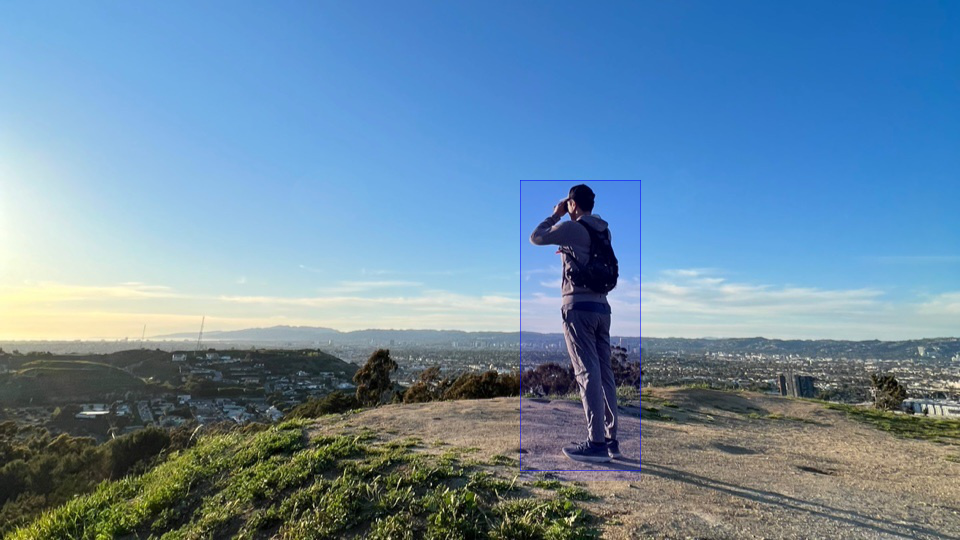

In [85]:
from PIL import Image
import numpy as np

im = Image.open("baldwin_hills.jpg")

#print(im.size) # (960, 540)

arr = np.asarray(im)
print(arr.shape, arr.dtype) # (540, 960, 3) uint8

arr = arr.astype(np.float64) # float로 변환


###
# 투명박스
arr[180:481, 520:641, :] = arr[180:481, 520:641, :] * (255 - 30)/255 + np.array((0,0,255.0)) * 30/255

# 투명박스 테두리
x, y, w, h = 520, 180, 120, 290
arr[y:y+h+1, x] = arr[y:y+h+1, x] * 0.5 + np.array((0,0,255.0)) * 0.5 #alpha = 0.5
arr[y:y+h+1, x+w] = arr[y:y+h+1, x+w] * 0.5 + np.array((0,0,255.0)) * 0.5 
arr[y, x:x+w+1] = arr[y, x:x+w+1] * 0.5 + np.array((0,0,255.0)) * 0.5 
arr[y+h, x:x+w+1] = arr[y+h, x:x+w+1] * 0.5 + np.array((0,0,255.0)) * 0.5 
###


arr = arr.clip(0,255)

print(arr.shape, arr.dtype)

im = Image.fromarray(arr.astype(np.uint8))

im

(270, 480, 3) uint8


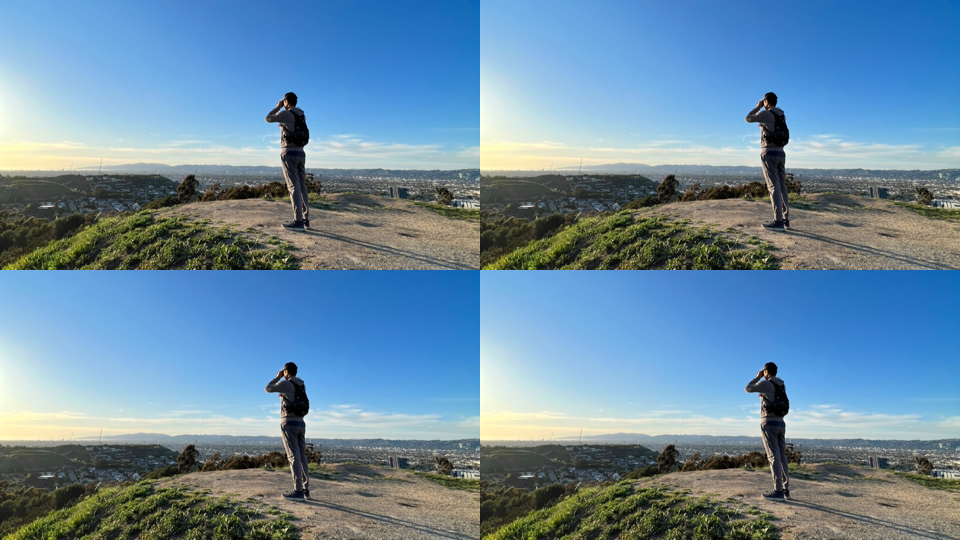

In [100]:
# 격자 형태로 배치

from PIL import Image
import numpy as np

im = Image.open("baldwin_hills.jpg").resize((480, 270))

#print(im.size) # (960, 540)

arr = np.asarray(im)
print(arr.shape, arr.dtype) # (540, 960, 3) uint8


###
# temp = arr
# x, y = 480, 270
# arr = arr.repeat(2, axis=0).repeat(2, axis=1)
# arr[:y, :x] = temp
# arr[y:2*y, :x] = temp
# arr[:y, x:2*x] = temp
# arr[y:2*y, x:2*x] = temp
###

###
arr = np.hstack([arr, arr])
arr = np.vstack([arr, arr])
###



im = Image.fromarray(arr)

im

[RGB를 YUV의 휘도(luminance)로 변환](https://en.wikipedia.org/wiki/YUV#Conversion_to/from_RGB) 

$Y = 0.2989 \times r + 0.5870 \times g + 0.1140 \times b$

주의: R, G, B 중 한 채널만 출력해도 흑백 이미지가 만들어집니다. 얼핏 봤을 때는 RGB를 모두 사용해서 휘도를 계산한 것과 한 채널만으로 흑백을 만든 것을 구분하지 못할 수도 있습니다. 세 채널 모두 사용해서 휘도를 계산하도록 주의하세요.

RGB값을 평균을 낸다음 같은 값으로 설정한다. 컴퓨터비전에서 인간의 눈이 밝기에 반응할때 녹색의 영향을 많이받는다고 하여 녹색 비중이 크고, 빨-파랑 순으로 비율 조정됨. 1/3씩 평등하게 비중을 나누지 않고 보기에 주어진 식으로 rgb값을 적당히 섞고 Y값을 이용해서 컬러값을 흑백으로 바꾼.

(540, 960, 3) uint8


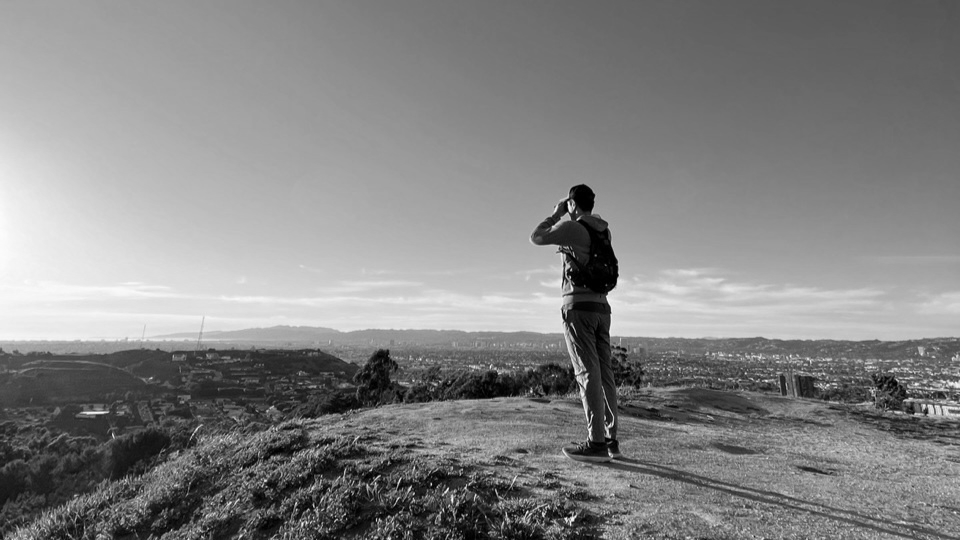

In [102]:
# 컬러에서 흑백

# hflip, vflip, downsize
from PIL import Image
import numpy as np

im = Image.open("baldwin_hills.jpg")

#print(im.size) # (960, 540)

arr = np.asarray(im)
print(arr.shape, arr.dtype) # (540, 960, 3) uint8


arr = 0.2989 * arr[:,:,0] + 0.5870*arr[:,:,1] + 0.1140*arr[:,:,2] 
#슬라이싱을 이용해서 red, blue, green 값을 직접 가져온다음 주어진 값을 곱해서 새로운 array 만듬
#주어진값을 곱한 arr은 float type임. 그래서 clip으로 범위 지정해서 astype으로 data type을 int로 변경함



im = Image.fromarray(arr.clip(0,255).astype(np.uint8)) # data type 바꿔주기

im
